# LAB 09 — NER fine-tuning và Information Extraction


In [3]:
import sys, json, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
LAB_DIR = Path.cwd() / 'lab9' if (Path.cwd() / 'lab9/baseline_ner.py').is_file() else Path.cwd()
sys.path.insert(0, str(LAB_DIR.resolve()))
import baseline_ner as ner
ner.configure()
model_path = ner.assets()
tokenizer = ner.BertTokenizerFast.from_pretrained(model_path, do_lower_case=True)
data = json.loads((ner.CACHE/'data.json').read_text(encoding='utf-8'))
print({split: len(rows) for split, rows in data.items()})

{'train': 14041, 'validation': 3250, 'test': 3453}


#### 13. Baseline

Token features → DictVectorizer → SGD linear classifier (logistic loss) → BIO. Đặc trưng gồm word, prefix/suffix, chữ hoa, chữ số, shape và từ lân cận. Vectorizer chỉ fit train. `run()` huấn luyện baseline trước rồi fine-tune Transformer; các lần mở báo cáo có thể đọc kết quả đã lưu.


In [4]:
if not (ner.CACHE/'evidence.json').exists():
    ner.run()
evidence = json.loads((ner.CACHE/'evidence.json').read_text(encoding='utf-8'))
display(pd.DataFrame([evidence['results'][0]]))
print(inspect.getsource(ner.TokenFeatureBaseline))

class TokenFeatureBaseline:
    def fit(self,rows):
        self.vectorizer=DictVectorizer(dtype=np.float32)
        x=self.vectorizer.fit_transform([features(r['words'],i) for r in rows for i in range(len(r['words']))])
        y=[tag for r in rows for tag in r['tags']]
        self.classifier=SGDClassifier(loss='log_loss',alpha=1e-5,max_iter=30,tol=1e-4,random_state=SEED)
        self.classifier.fit(x,y);return self
    def predict(self,rows):
        x=self.vectorizer.transform([features(r['words'],i) for r in rows for i in range(len(r['words']))])
        labels=self.classifier.predict(x).tolist();out=[];offset=0
        for row in rows:
            n=len(row['words']);out.append(labels[offset:offset+n]);offset+=n
        return out



,Model,Training time (s),Precision,Recall,F1,TP,FP,FN,Gold entities
0,Baseline,6.548966,0.673727,0.709632,0.691213,4008,1941,1640,5648


#### 14. Transformer Token Classification

Input text → Tokenizer → Input IDs → Pretrained Transformer → hidden representation → Linear → logits for every token → BIO labels. BERT-Tiny 2 layers, d=128, 2 heads; head Linear(128,9), không dùng [CLS] để gán một nhãn cho câu.


In [5]:
print(inspect.getsource(ner.PretrainedTokenClassifier))
print(pd.DataFrame(evidence['history']).to_string(index=False))

class PretrainedTokenClassifier(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__();path=CACHE/'bert-tiny'
        config=BertConfig.from_pretrained(path);config._attn_implementation='eager'
        self.encoder=BertModel.from_pretrained(path,config=config,add_pooling_layer=False) if pretrained else BertModel(config,add_pooling_layer=False)
        self.dropout=nn.Dropout(.1);self.token_classifier=nn.Linear(config.hidden_size,len(TAGS))
    def forward(self,input_ids,attention_mask):
        contextual_representations=self.encoder(input_ids=input_ids,attention_mask=attention_mask).last_hidden_state
        token_logits=self.token_classifier(self.dropout(contextual_representations))
        return token_logits

 Epoch  Train loss  Validation F1
     1    0.237170       0.797985
     2    0.109615       0.840315
     3    0.072531       0.844341
     4    0.050904       0.848707


#### 16. Core Implementation

Strategy A được dùng nhất quán khi train, validation, test và IE. Câu dài được chia thành chunk ở ranh giới word rồi ghép dự đoán; không cắt mất word ở test. Chunking vẫn làm mất context xuyên chunk. Dự đoán I-X không hợp lệ được đọc theo quy tắc CoNLL: mở chunk X mới; TP vẫn phải khớp đúng span và loại.


In [6]:
from information_extraction import load
model, tokenizer = load()
row = data['test'][0]
encoded, aligned_labels = ner.align(tokenizer, row['words'], row['tags'])
with torch.no_grad():
    logits = model(torch.tensor([encoded['input_ids']]), torch.tensor([encoded['attention_mask']]))
display(pd.DataFrame({'tokens':tokenizer.convert_ids_to_tokens(encoded['input_ids']),
 'input_ids':encoded['input_ids'],'attention_mask':encoded['attention_mask'],
 'word_ids':encoded.word_ids(),'labels':aligned_labels,
 'predictions':[ner.TAGS[i] for i in logits.argmax(-1)[0].tolist()]}))
print('logits shape:',tuple(logits.shape)); print('logits first 3 positions:',logits[0,:3])

logits shape: (1, 14, 9)
logits first 3 positions: tensor([[ 5.7154, -3.3054, -3.9915, -1.7008, -2.5543,  4.1005, -0.0856, -0.9188,
         -1.5682],
        [ 9.4610, -1.5228, -3.2415, -1.0802, -2.0142, -1.2026, -2.6288, -2.3070,
         -2.7302],
        [ 9.8304, -2.0574, -2.9885, -2.3169, -1.4526, -1.8822, -1.5940, -2.1725,
         -1.4326]])


,tokens,input_ids,attention_mask,word_ids,labels,predictions
0,[CLS],101,1,NaN,-100,O
1,soccer,4715,1,0.0,0,O
2,-,1011,1,1.0,0,O
3,japan,2900,1,2.0,5,B-LOC
4,get,2131,1,3.0,0,O
5,lucky,5341,1,4.0,0,O
6,win,2663,1,5.0,0,O
7,",",1010,1,6.0,0,O
8,china,2859,1,7.0,1,B-LOC
9,in,1999,1,8.0,0,O


#### 17. Experiment 1 — Tokenization Analysis

Phân tích 40 câu test đầu, không dùng số liệu này để điều chỉnh model. Số tokens trong R chỉ tính subword nội dung, loại [CLS]/[SEP]. # subword splits là số word sinh nhiều hơn một mảnh.


In [7]:
tokenization_rows=[]; word_stats=[]
for sid,row in enumerate(data['test'][:40]):
    enc=tokenizer(row['words'],is_split_into_words=True,add_special_tokens=False)
    counts=np.bincount(enc.word_ids(),minlength=len(row['words']))
    tokenization_rows.append({'Sentence':sid,'# words':len(counts),'# tokens':len(enc['input_ids']),
       '# subword splits':int((counts>1).sum()),'R':len(enc['input_ids'])/len(counts),
       'Length group':'short (≤15 words)' if len(counts)<=15 else 'long (>15 words)'})
    word_stats.extend({'Word':w,'Entity':tag!='O','Pieces':int(n)} for w,tag,n in zip(row['words'],row['tags'],counts))
tokenization_table=pd.DataFrame(tokenization_rows); display(tokenization_table)
display(tokenization_table.groupby('Length group')[['# words','# tokens','# subword splits','R']].mean())
word_table=pd.DataFrame(word_stats)
display(word_table.groupby('Entity').agg(Words=('Word','size'),Mean_pieces=('Pieces','mean'),Split_rate=('Pieces',lambda s:(s>1).mean())))
display(word_table[word_table.Pieces>1].sort_values('Pieces',ascending=False).head(12))

,Sentence,# words,# tokens,# subword splits,R,Length group
0,0,12,12,0,1.000000,short (≤15 words)
1,1,2,4,2,2.000000,short (≤15 words)
2,2,6,12,2,2.000000,short (≤15 words)
3,3,25,27,1,1.080000,long (>15 words)
4,4,25,27,1,1.080000,long (>15 words)
5,5,42,51,5,1.214286,long (>15 words)
6,6,23,29,2,1.260870,long (>15 words)
7,7,17,17,0,1.000000,long (>15 words)
8,8,18,18,0,1.000000,long (>15 words)
9,9,28,28,0,1.000000,long (>15 words)


,# words,# tokens,# subword splits,R
Length group,,,,
long (>15 words),27.416667,32.791667,3.083333,1.145476
short (≤15 words),8.812500,10.562500,0.937500,1.397204


,Words,Mean_pieces,Split_rate
Entity,,,
False,646,1.080495,0.040248
True,153,1.686275,0.411765


,Word,Entity,Pieces
661,Cristofoletto,True,5
19,1996-12-06,False,5
451,30-year-old,False,5
431,1996-12-06,False,5
703,1996-12-06,False,5
125,unstoppable,False,4
655,Giovanelli,True,4
673,Giambatista,True,4
680,Mazzucato,True,4
658,Checchinato,True,4


**Những loại từ nào thường bị chia?** 

Tên riêng ít gặp, dạng biến thể, từ ghép và các chuỗi không có nguyên dạng trong vocabulary có thể cần nhiều mảnh. Bảng trên cho các trường hợp quan sát được ở 40 câu; việc chia phụ thuộc vocabulary, không đủ để kết luận từ hiếm trong corpus pretraining. R là số mảnh/word, không phải tỷ lệ lỗi.


#### 18. Experiment 2 — Baseline vs Transformer

Cùng toàn bộ test set gốc, cùng chuẩn BIO và exact entity matching. Thời gian baseline chỉ gồm fit; thời gian Transformer gồm train và validation, không gồm test/download hoặc pretraining.


In [8]:
display(pd.DataFrame(evidence['results'])[['Model','Precision','Recall','F1']])
display(pd.DataFrame(evidence['results'])[['Model','Training time (s)']])

,Model,Precision,Recall,F1
0,Baseline,0.673727,0.709632,0.691213
1,Pretrained Transformer,0.770727,0.799929,0.785056


,Model,Training time (s)
0,Baseline,6.548966
1,Pretrained Transformer,114.737740


#### 19. Experiment 3 — Entity-Level Evaluation

Gold `New/B-LOC York/I-LOC`, prediction `New/B-LOC York/O`: đúng 1/2 nhãn token nhưng entity TP=0, FP=1, FN=1; F1 entity=0. Span chỉ đúng khi cả đầu, cuối và loại khớp. O không được tính thành entity.


Token accuracy including O (auxiliary): 0.9588672337676322


,Level,Precision,Recall,F1
0,Token BIO (excluding O),0.832294,0.822855,0.827548
1,Entity exact span+type,0.770727,0.799929,0.785056


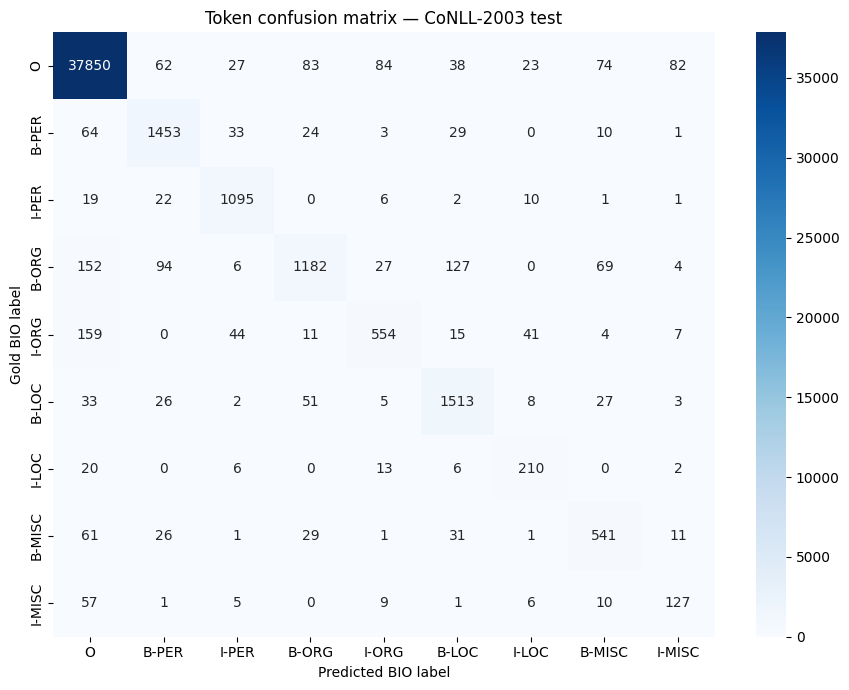

In [9]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
gold=evidence['gold']; predictions=evidence['transformer']
flat_gold=sum(gold,[]); flat_pred=sum(predictions,[])
p,r,f1,_=precision_recall_fscore_support(flat_gold,flat_pred,labels=ner.TAGS[1:],average='micro',zero_division=0)
display(pd.DataFrame([{'Level':'Token BIO (excluding O)','Precision':p,'Recall':r,'F1':f1},
 {'Level':'Entity exact span+type',**{k:v for k,v in ner.score(gold,predictions).items() if k in ['Precision','Recall','F1']}}]))
print('Token accuracy including O (auxiliary):',accuracy_score(flat_gold,flat_pred))
cm=confusion_matrix(flat_gold,flat_pred,labels=ner.TAGS)
fig,ax=plt.subplots(figsize=(9,7));sns.heatmap(cm,annot=True,fmt='d',xticklabels=ner.TAGS,yticklabels=ner.TAGS,ax=ax,cmap='Blues')
ax.set(xlabel='Predicted BIO label',ylabel='Gold BIO label',title='Token confusion matrix — CoNLL-2003 test')
plt.tight_layout();fig.savefig(LAB_DIR/'confusion_matrix.png',dpi=150);plt.show()

#### 20. Precision / Recall / F1

P=TP/(TP+FP), R=TP/(TP+FN), F1=2TP/(2TP+FP+FN). TP là tuple (sentence,start,end,type) xuất hiện trong cả gold và prediction; sai loại hoặc sai ranh giới tạo FP và FN. Mỗi câu có chỉ số riêng để entity trùng tên ở các câu không bị gộp.


In [10]:
display(pd.DataFrame([ner.score(gold,predictions)]))

,Precision,Recall,F1,TP,FP,FN,Gold entities
0,0.770727,0.799929,0.785056,4518,1344,1130,5648


#### 21. Experiment 4 — Entity Type Analysis

So sánh PER/ORG/LOC/MISC bằng entity metrics; thống kê số entity train để hỗ trợ diễn giải.


In [11]:
display(pd.DataFrame(evidence['type_metrics'])[['Entity','Precision','Recall','F1']])
from collections import Counter
type_counts=Counter(kind for row in data['train'] for a,b,kind in ner.spans(row['tags']))
display(pd.DataFrame(type_counts.items(),columns=['Entity','Train entities']))

,Entity,Precision,Recall,F1
0,PER,0.798654,0.880643,0.837647
1,ORG,0.739044,0.670078,0.702873
2,LOC,0.827873,0.893885,0.859614
3,MISC,0.634715,0.698006,0.664858


,Entity,Train entities
0,ORG,6321
1,MISC,3438
2,PER,6600
3,LOC,7140


**Vì sao performance khác nhau giữa các loại?** 

Số lượng mẫu train ảnh hưởng cơ hội học; PER có mẫu tên người, ORG thường có nhiều từ và dấu hiệu tổ chức nhưng cũng có viết tắt, LOC có thể trùng tên người/đội thể thao. MISC gộp nhiều nhóm như quốc tịch và sự kiện. Context, boundary và miền tin tức thể thao/chính trị cùng ảnh hưởng. Bảng train counts và F1 là bằng chứng mô tả; chưa có ablation để xác định riêng tác động của từng yếu tố.


Trong kết quả này, LOC có F1 cao nhất (0.8596), tiếp theo PER (0.8376), ORG (0.7029) và MISC (0.6649). ORG recall 0.6701 cho thấy còn bỏ sót nhiều entity; các ví dụ context ở mục 24 minh họa tên địa điểm đồng thời được dùng làm tên đội/tổ chức. Các số đo mô tả hiện tượng, chưa xác nhận một nguyên nhân duy nhất.


#### 22. Experiment 5 — Entity Length

Nhóm theo số word gốc của entity, không theo WordPiece. Precision nhóm dùng predicted spans có độ dài tương ứng, recall dùng gold spans tương ứng; span dự đoán sai độ dài có thể tạo FP/FN ở hai nhóm khác nhau.


,Entity length,F1
0,1,0.776645
1,2,0.836247
2,3,0.636792
3,4+,0.297030


,Entity length,Gold entities,TP,FP,FN
0,1,3574,2933,1046,641
1,2,1776,1435,221,341
2,3,236,135,53,101
3,4+,62,15,24,47


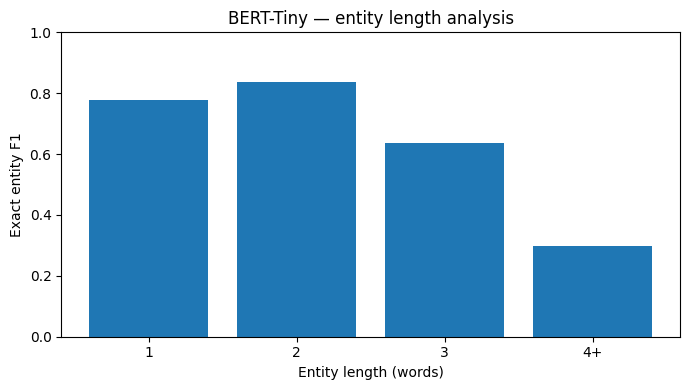

,Train frequency,Gold entities,Exact matches,Recall
0,Unseen (0),2500,1740,0.696000
1,Rare (1–2),613,463,0.755302
2,Frequent (3+),2535,2315,0.913215


In [12]:
length_table=pd.DataFrame(evidence['length']);display(length_table[['Entity length','F1']])
display(length_table[['Entity length','Gold entities','TP','FP','FN']])
fig,ax=plt.subplots(figsize=(7,4));ax.bar(length_table['Entity length'],length_table.F1)
ax.set(xlabel='Entity length (words)',ylabel='Exact entity F1',ylim=(0,1),title='BERT-Tiny — entity length analysis')
plt.tight_layout();fig.savefig(LAB_DIR/'entity_length_analysis.png',dpi=150);plt.show()
analysis=ner.analyze_predictions(data,gold,predictions)
display(pd.DataFrame(analysis['rarity']))

**Đối chiếu Prediction 2–3:** 

F1 các nhóm 1/2/3/4+ lần lượt là 0.7766, 0.8362, 0.6368, 0.2970. Độ dài không phải yếu tố duy nhất: loại và tần suất entity phân bố khác nhau giữa nhóm. Recall unseen/rare/frequent là 0.6960, 0.7553, 0.9132. Đây là kiểm tra giả thuyết về mức hiếm, không tách được nhân quả khỏi context và loại entity.


Prediction 2 được hỗ trợ ở nhóm 3 và 4+ từ, nhưng không đúng nhất quán: nhóm 2 từ có F1 cao hơn nhóm 1 từ. Nhóm 4+ chỉ có 62 gold entities nên kết quả cũng nhạy với số mẫu ít. Prediction 3 được hỗ trợ theo recall: unseen thấp hơn rare và frequent; đây là tương quan trên test hiện tại.


#### 23. Experiment 6 — Error Analysis

Chọn theo thứ tự cố định từ test: 5 FP, 5 FN, 5 cặp boundary sai có cùng loại và chồng lấn. Năm FP/FN đầu được chọn ngoài các span dùng cho boundary để tránh lặp cùng lỗi. Một entity bị sai boundary được tính cả FP và FN trong metric.


In [13]:
display(pd.DataFrame(analysis['errors'])[['Text','Gold','Prediction','Error type','Explanation']])

,Text,Gold,Prediction,Error type,Explanation
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",CHINA / PER,CHINA / LOC,wrong entity type,Prediction không có span khớp gold; surface xu...
1,The former Soviet republic was playing in an A...,Soviet / MISC,Soviet republic / LOC,wrong entity type,Prediction không có span khớp gold; surface xu...
2,Defender Hassan Abbas rose to intercept a long...,Bitar / PER,Bitar / LOC,wrong entity type,Prediction không có span khớp gold; surface xu...
3,"Japan , co-hosts of the World Cup in 2002 and ...",∅,world / MISC,spurious entity,Prediction không có span khớp gold; surface xu...
4,"Japan , co-hosts of the World Cup in 2002 and ...",FIFA / ORG,FIFA / MISC,wrong entity type,Prediction không có span khớp gold; surface xu...
5,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",CHINA / PER,CHINA / LOC,wrong entity type,Gold không có span khớp prediction; surface xu...
6,The former Soviet republic was playing in an A...,Soviet / MISC,Soviet republic / LOC,wrong entity type,Gold không có span khớp prediction; surface xu...
7,Defender Hassan Abbas rose to intercept a long...,Bitar / PER,Bitar / LOC,wrong entity type,Gold không có span khớp prediction; surface xu...
8,Bitar pulled off fine saves whenever they did .,Bitar / PER,∅,missing entity,Gold không có span khớp prediction; surface xu...
9,"Japan , co-hosts of the World Cup in 2002 and ...",FIFA / ORG,FIFA / MISC,wrong entity type,Gold không có span khớp prediction; surface xu...


#### 24. Context Analysis

Ba surface form trong test có hai loại gold khác nhau. Không tạo ví dụ thay cho dữ liệu thật; chỉ số câu và dự đoán được lưu để đối chiếu.


In [14]:
display(pd.DataFrame(analysis['contexts']))

,Surface,Gold type,Sentence,Text,Predicted spans
0,ARIZONA,ORG,518,ARIZONA 6 7 0 248 332,"[(0, 1, 'ORG')]"
1,ARIZONA,LOC,545,DALLAS AT ARIZONA,"[(2, 3, 'LOC')]"
2,ATLANTA,ORG,451,ATLANTA 10 8 .556 7,"[(0, 1, 'ORG')]"
3,ATLANTA,LOC,3295,TORONTO AT ATLANTA,"[(2, 3, 'LOC')]"
4,American,MISC,893,"In a statement Havel , who is recovering from ...","[(29, 30, 'MISC')]"
5,American,ORG,1016,The conditions for clearance of the alliance w...,"[(12, 13, 'MISC')]"


**Vì sao contextual representation có lợi?** Cùng một tên có thể chỉ địa điểm, người hay đội/tổ chức tùy câu. Static embedding gán cùng vector cho cùng từ, trong khi Transformer kết hợp thông tin câu tại mỗi lần xuất hiện. Baseline ở đây cũng có hai từ lân cận nhưng không học context nhiều vị trí như encoder. Các ví dụ có gold khác nhau cho thấy cần context; dự đoán thực tế trong bảng mới cho biết model phân biệt thành công hay chưa.


#### 25. Application — Information Extraction

Raw text → tokenize → token classifier → BIO spans → structured representation. Schema Option A: PER→PERSON, ORG→ORG, LOC→LOCATION; MISC không xuất trong schema nhưng vẫn được đánh giá ở NER.


In [15]:
from information_extraction import extract, gold_corpus, structured
text='Barack Obama visited Paris.'
print(json.dumps(extract(text,model,tokenizer),ensure_ascii=False,indent=2))

{
  "PERSON": [
    "Barack Obama"
  ],
  "ORG": [],
  "LOCATION": [
    "Paris"
  ]
}


#### 26. Mini Information Extraction Task — Option A (News)

Dùng 30 câu kiểu tin tức tự biên soạn trong `information_extraction.py`. Đây là corpus kiểm tra có kiểm soát, không phải các sự kiện báo chí được xác minh. Gold PERSON/ORG/LOCATION được gán thủ công theo danh sách tên trước khi dự đoán; span xác định bằng vị trí xuất hiện duy nhất của tên. Không dùng 30 câu này để train, chọn epoch hay sửa nhãn theo prediction.


In [16]:
ie_rows=gold_corpus()
display(pd.DataFrame([{'Text':row['text'],'Gold':structured(row['words'],row['tags'])} for row in ie_rows]))

,Text,Gold
0,Barack Obama spoke at United Nations in New York.,"{'PERSON': ['Barack Obama'], 'ORG': ['United N..."
1,"In Berlin, Angela Merkel met representatives o...","{'PERSON': ['Angela Merkel'], 'ORG': ['Europea..."
2,UNESCO invited Emmanuel Macron to a conference...,"{'PERSON': ['Emmanuel Macron'], 'ORG': ['UNESC..."
3,A reporter in Brussels asked Joe Biden about N...,"{'PERSON': ['Joe Biden'], 'ORG': ['NATO'], 'LO..."
4,Rishi Sunak discussed the work of BBC during a...,"{'PERSON': ['Rishi Sunak'], 'ORG': ['BBC'], 'L..."
5,Justin Trudeau spoke at Reuters in Ottawa.,"{'PERSON': ['Justin Trudeau'], 'ORG': ['Reuter..."
6,"In California, Tim Cook met representatives of...","{'PERSON': ['Tim Cook'], 'ORG': ['Apple'], 'LO..."
7,Microsoft invited Satya Nadella to a conferenc...,"{'PERSON': ['Satya Nadella'], 'ORG': ['Microso..."
8,A reporter in London asked Sundar Pichai about...,"{'PERSON': ['Sundar Pichai'], 'ORG': ['Google'..."
9,Elon Musk discussed the work of Tesla during a...,"{'PERSON': ['Elon Musk'], 'ORG': ['Tesla'], 'L..."


#### 27. Evaluation của Information Extraction

Exact entity-level span và type, trên 30 câu có tổng 90 entity gold. Schema giữ cùng loại PER/ORG/LOC khi so khớp. Tập nhỏ, chủ yếu câu rõ ràng theo năm mẫu và tên nổi tiếng; điểm số không đại diện cho toàn bộ tin tức thực tế.


In [17]:
from information_extraction import evaluate_ie
ie=json.loads((ner.CACHE/'ie_results.json').read_text(encoding='utf-8')) if (ner.CACHE/'ie_results.json').exists() else evaluate_ie()
display(pd.DataFrame([ie['metrics']]))
display(pd.DataFrame(ie['examples'])[['Text','Gold','Prediction']])

,Precision,Recall,F1,TP,FP,FN,Gold entities
0,0.868132,0.877778,0.872928,79,12,11,90


,Text,Gold,Prediction
0,Barack Obama spoke at United Nations in New York.,"{'PERSON': ['Barack Obama'], 'ORG': ['United N...","{'PERSON': ['Barack Obama'], 'ORG': ['United N..."
1,"In Berlin, Angela Merkel met representatives o...","{'PERSON': ['Angela Merkel'], 'ORG': ['Europea...","{'PERSON': ['Angela Merkel'], 'ORG': ['Europea..."
2,UNESCO invited Emmanuel Macron to a conference...,"{'PERSON': ['Emmanuel Macron'], 'ORG': ['UNESC...","{'PERSON': ['Emmanuel Macron'], 'ORG': ['UNESC..."
3,A reporter in Brussels asked Joe Biden about N...,"{'PERSON': ['Joe Biden'], 'ORG': ['NATO'], 'LO...","{'PERSON': ['Joe'], 'ORG': ['NATO'], 'LOCATION..."
4,Rishi Sunak discussed the work of BBC during a...,"{'PERSON': ['Rishi Sunak'], 'ORG': ['BBC'], 'L...","{'PERSON': ['Rishi Sunak'], 'ORG': ['BBC'], 'L..."
5,Justin Trudeau spoke at Reuters in Ottawa.,"{'PERSON': ['Justin Trudeau'], 'ORG': ['Reuter...","{'PERSON': ['Justin Trudeau'], 'ORG': ['Reuter..."
6,"In California, Tim Cook met representatives of...","{'PERSON': ['Tim Cook'], 'ORG': ['Apple'], 'LO...","{'PERSON': ['Tim Cook'], 'ORG': ['Apple'], 'LO..."
7,Microsoft invited Satya Nadella to a conferenc...,"{'PERSON': ['Satya Nadella'], 'ORG': ['Microso...","{'PERSON': ['Satya Nadella'], 'ORG': ['Microso..."
8,A reporter in London asked Sundar Pichai about...,"{'PERSON': ['Sundar Pichai'], 'ORG': ['Google'...","{'PERSON': ['Sundar Pichai'], 'ORG': ['Google'..."
9,Elon Musk discussed the work of Tesla during a...,"{'PERSON': ['Elon Musk'], 'ORG': ['Tesla'], 'L...","{'PERSON': [], 'ORG': ['Elon Musk', 'Tesla'], ..."


**Observation:** IE Precision=0.8681, Recall=0.8778, F1=0.8729. **Evidence:** TP=79, FP=12, FN=11 từ đối chiếu gold ở 30 câu. **Interpretation:** đây là mức trích xuất trên tập câu tự biên soạn, chưa chứng minh khả năng tổng quát trên một corpus news mới.


#### 29. Deliverables và Reproducibility

Model `prajjwal1/bert-tiny`, revision `6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837`; tokenizer uncased WordPiece; alignment A, ignore=-100; max length 128 theo chunk, batch 32, AdamW lr=0.0003, weight_decay=0.01, 4 epochs, seed 42, clipping=1.0. Chọn epoch theo validation entity F1 cao nhất; mọi test word được đánh giá. CPU 4 threads. Thời gian baseline 6.55s, Transformer 114.74s. Model/dataset/checkpoint/evidence nằm trong `.lab9_cache/` ngoài bộ nộp.


In [18]:
import platform,importlib.metadata as metadata
print('Python',platform.python_version(),'torch',torch.__version__)
for name in ['transformers','numpy','pandas','scikit-learn']: print(name,metadata.version(name))
print((ner.CACHE/'dataset_info.json').read_text(encoding='utf-8'))
display(pd.read_csv(LAB_DIR/'results.csv'))

Python 3.12.7 torch 2.11.0+cpu
transformers 5.22.2
numpy 1.26.4
pandas 2.2.2
scikit-learn 1.5.2
{
  "source": "tomaarsen/conll2003",
  "revision": "3a0c0677d3177b6122fceed3239dda7a5de6a514",
  "sha256": {
    "train": "28924b53e43ec4d741cbef16d8a6245a77f404a77f18d44e256f95fa29acb59b",
    "validation": "0aa0bd59cf9ac8f60252d8194a8a223b650daba50f8e5a79284abf85420bfe84",
    "test": "9242163e112f99b43c32b663c6d6f7d5df64de73e19e02fcac789935f72565b8"
  }
}


,Model,Training time (s),Precision,Recall,F1,TP,FP,FN,Gold entities
0,Baseline,6.548966,0.673727,0.709632,0.691213,4008,1941,1640,5648
1,Pretrained Transformer,114.737740,0.770727,0.799929,0.785056,4518,1344,1130,5648


#### 32. Reflection

Pretrained Transformer → contextual representation → [CLS] → sequence head → sequence label; hoặc → every token → token classifier → NER labels.


Sau LAB 08, tôi dùng pretrained Transformer để dự đoán một nhãn sentiment cho cả review. Sang LAB 09, encoder vẫn tạo contextual representation tại mọi vị trí. Điểm thay đổi nằm ở cách đọc các vector đó và mục tiêu học của prediction head. Vì vậy, cùng một kiến trúc encoder có thể phục vụ nhiều bài toán mà không cần thiết kế lại toàn bộ mạng.

Với sequence classification, bài trước lấy vector ở vị trí [CLS], đưa qua Linear rồi dự đoán positive hoặc negative. Trong token classification, Linear được áp dụng chung cho từng vector trong chuỗi. Nếu hidden states có shape B×T×d thì logits có shape B×T×C. Mỗi vị trí nhận chín điểm số BIO thay vì cả câu chỉ nhận hai điểm số sentiment. Đổi head cũng đồng nghĩa đổi nhãn đích, loss và cách đánh giá; không phải một head mới tự hoạt động tốt ngay khi khởi tạo.

Pretraining cung cấp điểm xuất phát đã học từ văn bản, còn fine-tuning điều chỉnh representation cho ranh giới và loại entity. Trong thí nghiệm, baseline entity F1 đạt 0.6912, BERT-Tiny đạt 0.7851. Các số đo này phản ánh hai cấu hình trên cùng CoNLL-2003 test, không chứng minh encoder hiểu mọi tên riêng. Baseline có đặc trưng chữ hoa và từ lân cận, trong khi tokenizer BERT-Tiny uncased bỏ thông tin hoa thường, nên sự so sánh còn gắn với lựa chọn biểu diễn.

Khó khăn mới là annotation theo word nhưng encoder đọc subword. Tôi chọn chỉ giám sát mảnh đầu, đặt -100 cho phần còn lại và special tokens. Những mảnh bị bỏ khỏi loss vẫn tham gia attention. Khi đánh giá, dự đoán được ghép về word; entity chỉ đúng nếu khớp cả loại lẫn hai đầu mút. Token accuracy cao do nhiều nhãn O không thay thế được entity F1.

Pipeline IE chuyển span sang PERSON, ORG và LOCATION. Gold của ba mươi câu tự biên soạn giúp đo lỗi cụ thể, nhưng câu theo mẫu và tên nổi tiếng còn đơn giản hơn tin tức tự nhiên. Entity hiếm, tên mơ hồ, domain mới và context vượt chunk vẫn là giới hạn. Tái sử dụng encoder tiết kiệm công sức xây kiến trúc, còn dữ liệu gán nhãn, alignment và tiêu chí đánh giá quyết định liệu mô hình có hữu ích cho tác vụ thực tế hay không.
